# Imports

In [1]:
import numpyro
numpyro.set_host_device_count(4)

import jax
import jax.numpy as jnp
print("JAX:", jax.__version__)
print("local device count:", jax.local_device_count())
print("local devices:")
for d in jax.local_devices():
    print("  ", d)
    
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS

from likelihood import (
    FD_gaussian_likelihood,
    FD_marg_fullnormal_gaussianlikelihood,
    draw_fluences_fullnormal_gaussmarg,
    FD_marg_halfnormal_nooverlap_gaussianlikelihood,
    draw_fluences_halfnormal_nooverlap_gaussmarg,
)
from model import (
    setup_model,
    make_orthogonal_poly_sed
)

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import arviz as az
import arviz_plots as azp
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

import random

JAX: 0.11.2
local device count: 4
local devices:
   cpu:0
   cpu:1
   cpu:2
   cpu:3


In [2]:
# import sys
# print(sys.executable)  # Should point to your venv path, not /mnt/sw/nix/...

In [3]:
# import tqdm.std

# # Force tqdm to use newlines and flush output instantly for Jupyter
# def line_printer(file):
#     def print_status(s):
#         file.write(s.replace("\r", "") + "\n")
#         file.flush()
#     return print_status

# tqdm.std.status_printer = line_printer

In [4]:
# import sys
# import tqdm.std

# class ThreadSafeStdOut:
#     def __init__(self, stream):
#         self.stream = stream
#     def write(self, s):
#         self.stream.write(s)
#         self.stream.flush()
#     def flush(self):
#         self.stream.flush()

# # Override tqdm's default output file handle
# tqdm.std.tqdm.stqdm_file = ThreadSafeStdOut(sys.stdout)

## Real data

#### Pulling the data

In [126]:
data = jnp.load('/mnt/home/hsiegel/FRBayes/data/event_22154974_BB.npz')
power, freq, time = data['power'], data['freq'], data['time']
freq = freq[::-1]
power = power[::-1, :]
native_dnu = float(jnp.median(jnp.abs(jnp.diff(freq))))   # native channel width, before averaging

# -------------------------------------------------------------------
# Frequency downsampling: average consecutive blocks of n_avg good channels.
# Blocks are formed from good channels after bad are thrown out, so every block contains exactly n_avg
# of them and the Gaussian approximation to the chi'^2 statistics is uniform across blocks
# (m -> n_avg * m). Blocks straddling masked regions therefore span a wider range of real
# frequency than n_avg contiguous channels; `freq_span` reports that, and the residual
# dispersion-smearing bias it causes is small and is corrected by the likelihood reweighting.
# some small number of channels may be dropped from the top of the band if they aren't in a full block of n_avg.
# -------------------------------------------------------------------
n_avg = 8

n_chan = freq.shape[0]
n_blocks = n_chan // n_avg
n_dropped = n_chan - n_blocks * n_avg   # trailing channels, dropped to keep m uniform

freq_blocks = freq[: n_blocks * n_avg].reshape(n_blocks, n_avg)
power_blocks = power[: n_blocks * n_avg].reshape(n_blocks, n_avg, -1)

freq = freq_blocks.mean(axis=1)          # block centre = mean of its members' frequencies
power = power_blocks.mean(axis=1)
freq_span = freq_blocks.max(axis=1) - freq_blocks.min(axis=1)

print(f"{n_chan} good channels -> {n_blocks} blocks of {n_avg} ({n_dropped} dropped); "
      f"block span median {float(jnp.median(freq_span)):.3f} MHz, max {float(freq_span.max()):.3f} MHz")

# Shift to relative time starting at t = 0 (prevents float32 phase rounding)
time_rel = jnp.asarray(time - time[0], dtype=jnp.float32)
freq_channels = jnp.asarray(freq, dtype=jnp.float32)[:, None]
data_reshaped = jnp.asarray(power, dtype=jnp.float32)

Nseg = time_rel.shape[0]
dt = time_rel[1] - time_rel[0]

# Off-pulse noise region (first 20% of time bins)
n_noise_bins = Nseg // 5
noise_data = data_reshaped[:, :n_noise_bins]

# Off-pulse baseline median and MAD estimate of time-domain std dev (sigma_td)
noise_median_estimates = jnp.median(noise_data, axis=1, keepdims=True)
mad = jnp.median(jnp.abs(noise_data - noise_median_estimates), axis=1, keepdims=True)
sigma_estimates = mad * 1.4826  # Time-domain std dev (varsigma_a) per channel

# -------------------------------------------------------------------
# Per-channel weights for the orthogonal spectral basis.
# These are the squared on-pulse matched-filter SNR per channel, i.e. a measurement of where
# the burst actually carries signal-to-noise. They define the metric in which the spectral
# basis polynomials are orthogonalized; weighting every channel equally instead leaves the
# gamma-beta degeneracy largely intact, because the SED spans orders of magnitude across the
# band. The weights are fixed from the data before sampling, so the basis is a fixed change of
# coordinates, not a parameter-dependent one.
# -------------------------------------------------------------------

def estimate_channel_weights(data_td, sigma_td, on_slice=None, threshold=0.1, n_smooth=5):
    """
    w_a proportional to (on-pulse SNR in channel a)^2, normalized to sum to 1.

    data_td:  (nfreq, ntime), baseline-subtracted
    sigma_td: (nfreq, 1) per-channel time-domain noise std
    on_slice: burst window; if None, found from the noise-weighted profile by extending
              outward from the peak while it exceeds `threshold` times the peak
    n_smooth: channels to smooth the weights over, since the per-channel SNR is itself noisy

    Returns (weights, on_slice).
    """
    d = jnp.asarray(data_td)
    s = jnp.asarray(sigma_td).reshape(-1)

    # Masked / zero-noise channels get zero weight
    inv_sigma = jnp.where(jnp.isfinite(s) & (s > 0), 1.0 / jnp.maximum(s, jnp.finfo(float).tiny), 0.0)

    if on_slice is None:
        profile = (d * inv_sigma[:, None]).sum(axis=0)
        peak = int(jnp.argmax(profile))
        cut = threshold * profile[peak]
        lo = hi = peak
        while lo > 0 and profile[lo - 1] > cut:
            lo -= 1
        while hi < profile.size - 1 and profile[hi + 1] > cut:
            hi += 1
        on_slice = slice(lo, hi + 1)

    n_on = on_slice.stop - on_slice.start
    snr_per_channel = d[:, on_slice].sum(axis=1) * inv_sigma / jnp.sqrt(n_on)

    # Negative values are noise fluctuations in channels with no signal
    weights = jnp.maximum(snr_per_channel, 0.0) ** 2
    if n_smooth > 1:
        weights = jnp.convolve(weights, jnp.ones(n_smooth) / n_smooth, mode="same")

    return weights / weights.sum(), on_slice


def orthogonal_spectral_basis(freq, weights, freq_ref):
    """
    Gram-Schmidt orthogonalization of {1, x, x^2} in the weighted metric, x = ln(nu/nu_r),
    returning the two non-constant basis functions normalized to unit weighted RMS.

    Orthogonalizing against the constant decouples the spectral shape from the fluence, since
    a constant in ln F is exactly a rescaling of A. The returned coefficients convert the
    sampled c1, c2 back to the conventional gamma, beta:
        gamma = gamma_c1 * c1 + gamma_c2 * c2,   beta = beta_c2 * c2.
    """
    x = jnp.log(jnp.asarray(freq).reshape(-1) / freq_ref)
    w = jnp.asarray(weights).reshape(-1)
    ip = lambda u, v: jnp.sum(w * u * v)

    P0 = jnp.ones_like(x)
    P1 = x - ip(x, P0) / ip(P0, P0) * P0
    P2 = x ** 2 - ip(x ** 2, P0) / ip(P0, P0) * P0 - ip(x ** 2, P1) / ip(P1, P1) * P1

    # Unit weighted RMS, so the sampled coefficients are O(1)
    P1 /= jnp.sqrt(ip(P1, P1) / w.sum())
    P2 /= jnp.sqrt(ip(P2, P2) / w.sum())

    # P1, P2 are polynomials in x, so the map back to gamma, beta is exact
    a1, b1 = jnp.polyfit(x, P1, 1)
    a2, b2, d2 = jnp.polyfit(x, P2, 2)
    return P1, P2, dict(gamma_c1=a1, gamma_c2=b2, beta_c2=a2)


channel_weights, on_slice = estimate_channel_weights(data_reshaped, sigma_estimates)

# Reference frequency chosen so that the dispersion delay shape (nu^-2) is orthogonal to a
# constant offset under the channel weights, which decouples DM from the arrival time.
# t_0 is then the arrival time at the frequency carrying the weighted-mean dispersion delay.
nu_inv2_mean = jnp.sum(channel_weights * jnp.asarray(freq) ** -2) / jnp.sum(channel_weights)
freq_channels_ref = float(nu_inv2_mean ** -0.5)
# freq_channels_ref = float(jnp.mean(freq_channels))
P1, P2, spectral_coeff_map = orthogonal_spectral_basis(jnp.asarray(freq), channel_weights, freq_channels_ref)

print(f"on-pulse window {on_slice} ({on_slice.stop - on_slice.start} bins)")

# Baseline subtract off-pulse median
data_reshaped = data_reshaped - noise_median_estimates

# Fourier domain data (d_tilde = dt * rfft(d_td))
data_reshaped_FFT = dt * jnp.fft.rfft(data_reshaped, axis=-1)

# --- CRITICAL: Convert time-domain MAD std dev to Fourier-domain noise std dev ---
# sigma_noise = dt * sigma_td * sqrt(L / 2)
sigma_noise = dt * sigma_estimates * jnp.sqrt(Nseg / 2.0)

# Zero/NaN guard for masked RFI channels
sigma_noise = jnp.where(
    (sigma_noise <= jnp.float32(0.0)) | jnp.isnan(sigma_noise),
    jnp.inf,
    sigma_noise,
)

# downsampling FD bins
fd_downsample = 4   # keep the lowest 1/fd_downsample of the Fourier bins

fourier_freqs_full = jnp.fft.rfftfreq(Nseg, d=dt)
n_keep = fourier_freqs_full.size // fd_downsample

# DC carries the per-channel baseline, which the model does not include, so it is dropped here;
# truncation removes Nyquist along with the rest of the upper band. Everything downstream uses
# exactly the bins returned, so the model and likelihood need not know how this was chosen.
keep = slice(1, n_keep)
fourier_freqs = fourier_freqs_full[keep]
data_reshaped_FFT = data_reshaped_FFT[:, keep]
if sigma_noise.shape[-1] > 1:
    sigma_noise = sigma_noise[:, keep]

print(f"Fourier truncation: keeping bins 1-{n_keep} of {fourier_freqs_full.size} "
      f"(up to {float(fourier_freqs[-1])/1e3:.1f} kHz of {float(fourier_freqs_full[-1])/1e3:.1f} kHz)")

820 good channels -> 102 blocks of 8 (4 dropped); block span median 3.125 MHz, max 4.688 MHz
on-pulse window slice(99, 174, None) (75 bins)
Fourier truncation: keeping bins 1-41 of 165 (up to 11.9 kHz of 48.7 kHz)


In [127]:
freq_channels_ref

443.1968688964844

# Setup orthog SED halfnormal marginalized model and sampler

In [128]:
# -------------------------------------------------------------------
# 2. Model Closure Setup
# -------------------------------------------------------------------

# Width of each frequency channel block in MHz, used for the intra-channel smearing term.
# freq_span is the distance from the first to the last channel centre in a frequency block, which is
# one channel short of the block's full width -- hence the + native_dnu.
# blocks vary in width when downsampling, since blocks can straddle dropped channels.
block_width = jnp.asarray(freq_span + native_dnu, dtype=jnp.float32)[:, None]

constants_dict = {
    "freq_channels_ref": freq_channels_ref,
    "DM_incoherent": 0.0,
    "channel_width": block_width,
}

# Orthogonal spectral basis: sample c1, c2 rather than gamma, beta. Over a factor-of-two band
# x = ln(nu/nu_r) and x^2 are nearly parallel, which makes gamma and beta strongly degenerate;
# P1 and P2 are orthogonal in the metric set by the per-channel weights, and orthogonal to the
# constant, which also decouples them from the fluence.
# print(f"Fisher rho(c1,c2) with refitted weights: "
#       f"{fisher_rho([jnp.asarray(P1).reshape(-1), jnp.asarray(P2).reshape(-1)], w_fit):+.4f}")

single_pulse_fn = setup_model(
    constants_dict=constants_dict,
    freqs_channels=freq_channels,
    times=time_rel,
    sed_fn=make_orthogonal_poly_sed(P1, P2),
    fourier_freqs=fourier_freqs,
)

# -------------------------------------------------------------------
# 3. Priors & NUTS Sampling
# -------------------------------------------------------------------
priors = {
    # TOA prior: Wide Gaussian centered at 1.15 ms with a 2 ms std dev
    "mean_arrival_time": dist.Uniform(0.00115-.0002, 0.00115+.0002),

    "sigma": dist.Uniform(5e-5, 1e-4),              # intrinsic width (s)
    "DM": dist.Uniform(-0.1, 0.1),                  # residual DM (pc cm^-3)
    "tau_ref": dist.Uniform(1e-5, 2e-3),            # scattering timescale (s)

    # Orthogonal basis coefficients, O(1) by construction (unit weighted RMS basis). These are
    # specific to this burst's basis and are not comparable between bursts; gamma and beta are
    # recorded as deterministic sites via spectral_coeff_map and are what should be reported.
    "c1": dist.Uniform(-3.0, 3.0),                  # linear basis coefficient
    "c2": dist.Uniform(-3.0, 3.0),                  # quadratic basis coefficient
}
n_pulses = 1
s_opt = 100.0

num_warmup = 1000
num_samples = 200
num_chains = 1

kernel = NUTS(FD_marg_halfnormal_nooverlap_gaussianlikelihood, dense_mass=True)
mcmc = MCMC(kernel, num_warmup=num_warmup, num_samples=num_samples, num_chains=num_chains, 
            chain_method="parallel")

# Fixed master key seed for reproducible sampling across runs
key_sampler, key_fluences = jax.random.split(jax.random.PRNGKey(1))

## Run Marginalized

In [130]:
mcmc.run(
    key_sampler,
    data_fd=data_reshaped_FFT,
    sigma_noise=sigma_noise,
    n_pulses=n_pulses,
    priors=priors,
    single_pulse_fn=single_pulse_fn,
    s_opt=s_opt,
    spectral_coeff_map=spectral_coeff_map,
    extra_fields=("num_steps","accept_prob","diverging","potential_energy")
)

sample: 100%|██████████| 1200/1200 [00:04<00:00, 286.75it/s, 7 steps of size 6.56e-01. acc. prob=0.88]


In [131]:
# -------------------------------------------------------------------
# 4. Extract Posteriors
# -------------------------------------------------------------------
samples = mcmc.get_samples()
extra = mcmc.get_extra_fields()

In [132]:
mcmc_data = az.from_numpyro(mcmc, log_likelihood={}, posterior_predictive={})

In [133]:
import pandas as pd
names = ["mean_arrival_time", "sigma", "DM", "tau_ref", "c1", "c2"]
X = np.stack([np.asarray(samples[k])[:, 0] for k in names])
C = np.corrcoef(X)
print(pd.DataFrame(np.round(C, 2), index=names, columns=names))

                   mean_arrival_time  sigma    DM  tau_ref    c1    c2
mean_arrival_time               1.00   0.46  0.33    -0.70  0.27  0.06
sigma                           0.46   1.00  0.11    -0.52  0.23 -0.07
DM                              0.33   0.11  1.00    -0.26  0.19  0.02
tau_ref                        -0.70  -0.52 -0.26     1.00 -0.40 -0.05
c1                              0.27   0.23  0.19    -0.40  1.00  0.60
c2                              0.06  -0.07  0.02    -0.05  0.60  1.00


In [134]:
az.summary(mcmc_data, round_to=3)

,mean,sd,eti89_lb,eti89_ub,ess_bulk,ess_tail,r_hat,mcse_mean,mcse_sd
DM[0],-7.000000e-03,0.000000e+00,-7.000000e-03,-7.000000e-03,232.925,163.594,NaN,0.000000e+00,0.000000e+00
beta[0],-1.429500e+01,7.560000e-01,-1.565900e+01,-1.315200e+01,298.219,136.022,NaN,4.400000e-02,7.700000e-02
c1[0],-5.210000e-01,6.000000e-03,-5.310000e-01,-5.110000e-01,189.686,94.050,NaN,0.000000e+00,1.000000e-03
c2[0],-1.570000e-01,8.000000e-03,-1.720000e-01,-1.450000e-01,298.219,136.022,NaN,0.000000e+00,1.000000e-03
gamma[0],-4.535000e+00,8.600000e-02,-4.659000e+00,-4.384000e+00,269.896,154.808,NaN,5.000000e-03,6.000000e-03
"gram[0, 0]",2.654912e+10,4.685825e+08,2.583055e+10,2.729840e+10,291.190,153.712,NaN,2.846405e+07,2.688271e+07
mean_arrival_time[0],1.000000e-03,0.000000e+00,1.000000e-03,1.000000e-03,292.802,145.767,NaN,0.000000e+00,0.000000e+00
rho_mf[0],3.157521e+07,2.784626e+05,3.114672e+07,3.201811e+07,294.620,153.712,NaN,1.691169e+04,1.590017e+04
sigma[0],0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,208.760,127.598,NaN,0.000000e+00,0.000000e+00
snr_mf[0],1.937930e+02,9.000000e-03,1.937780e+02,1.938040e+02,95.132,141.118,NaN,1.000000e-03,1.000000e-03


In [135]:
jnp.corrcoef(samples["c1"][:,0], samples["c2"][:,0])[0,1]

Array(0.59528476, dtype=float32)

In [136]:
ex = mcmc.get_extra_fields()
ns = jnp.array(ex["num_steps"])
print(f"gradients/sample: mean {ns.mean():.1f}  median {jnp.median(ns)}  max {ns.max()}")
print(f"at max tree depth: {100*jnp.mean(ns >= 2**10 - 1):.1f}%")   # adjust if max_tree_depth != 10
print(f"accept_prob: mean {jnp.array(ex['accept_prob']).mean():.3f}")
print(f"divergences: {int(jnp.array(ex['diverging']).sum())} / {len(ns)}")
print(f"step size: {float(mcmc.last_state.adapt_state.step_size):.3e}")
print(f"potential_energy: mean {jnp.array(ex['potential_energy']).mean():.1f}  sd {jnp.array(ex['potential_energy']).std():.2f}")

gradients/sample: mean 5.7  median 7.0  max 7
at max tree depth: 0.0%
accept_prob: mean 0.884
divergences: 0 / 200
step size: 6.560e-01
potential_energy: mean -18762.1  sd 1.82


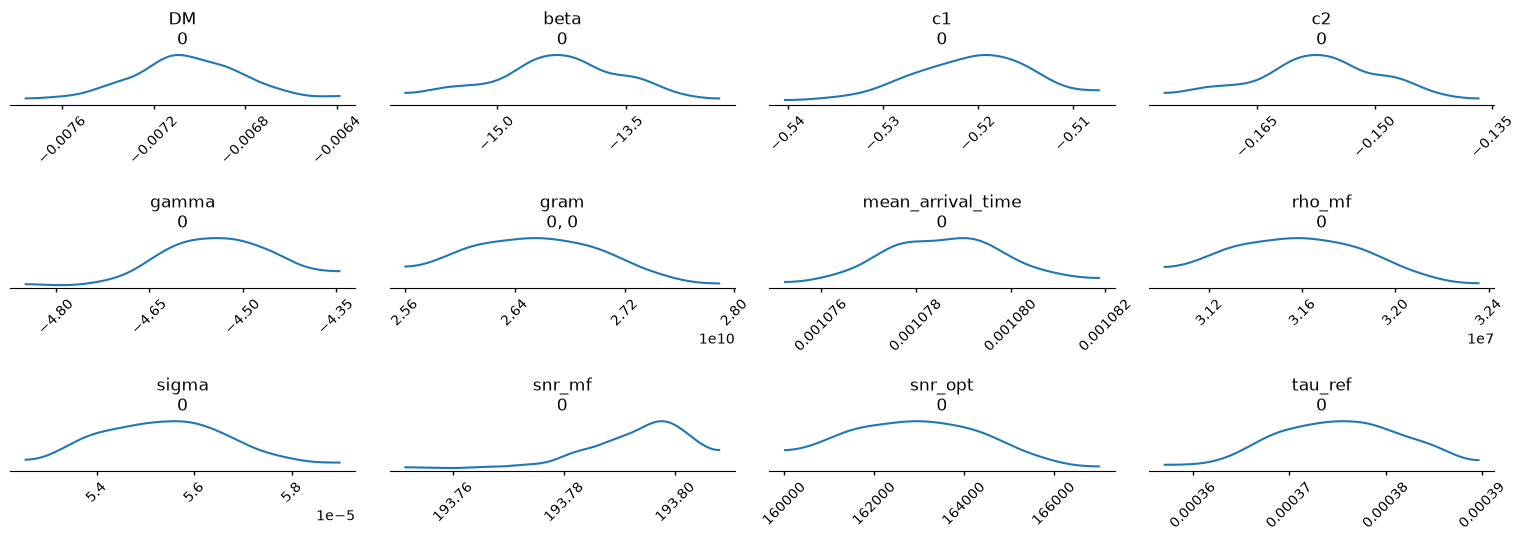

In [137]:
axes = azp.plot_dist(mcmc_data, stats=None)
for ax in plt.gcf().axes:
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))  # Limit to 4 ticks max
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.subplots_adjust(wspace=0.1)
plt.subplots_adjust(hspace=2.5)

# Remove all "mean" text annotations across all subplots
for ax in plt.gcf().axes:
    for text in list(ax.texts):
        if "mean" in text.get_text():
            text.remove()
            # Remove horizontal interval lines (they only have 2 x-data points)
    for line in list(ax.lines):
        if len(line.get_xdata()) <= 2:
            line.remove()
            # 3. Remove point estimate dots
    for collection in list(ax.collections):
        collection.remove()

plt.draw()

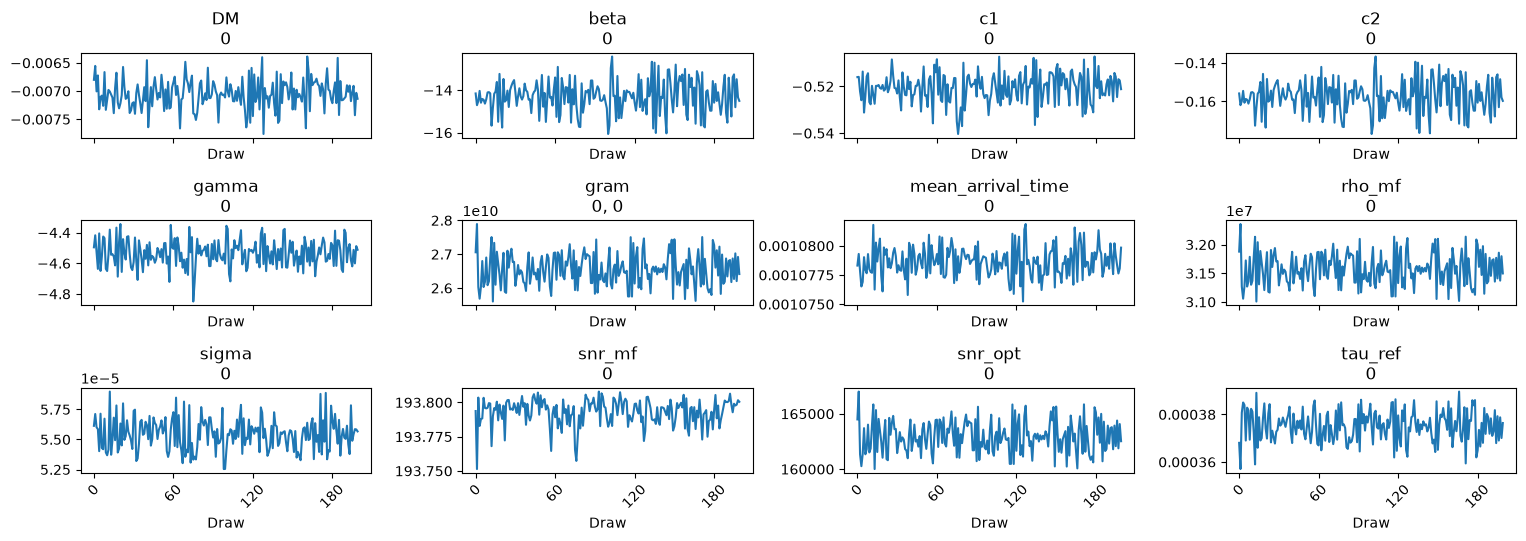

In [138]:
azp.plot_trace(mcmc_data)

# 2. Clean up x-axis tick clutter across all generated subplots
for ax in plt.gcf().axes:
    ax.xaxis.set_major_locator(ticker.MaxNLocator(nbins=4))
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [139]:
# -------------------------------------------------------------------
# 4. Reconstruct Fluences
# -------------------------------------------------------------------

fluences = draw_fluences_halfnormal_nooverlap_gaussmarg(
    snr_opt=samples["snr_opt"],
    snr_mf=samples["snr_mf"],
    s_opt=s_opt,
    key=key_fluences,
)

## Plot Residual

Plotting for Posterior Draw #189


/tmp/ipykernel_476677/3197561111.py:114: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


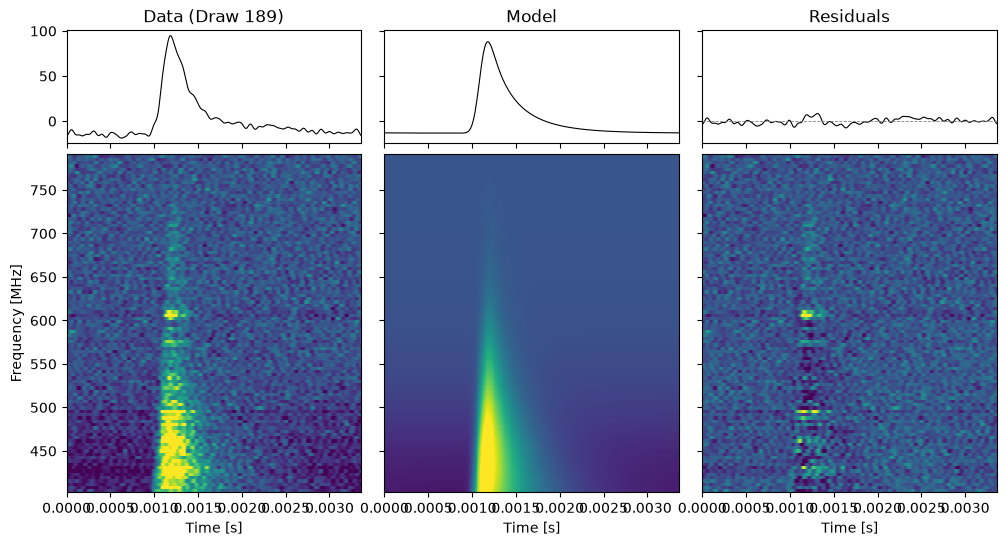

In [140]:
# -------------------------------------------------------------------
# 1. Extract a Random Posterior Draw & Evaluate Forward Model
# -------------------------------------------------------------------
# samples = mcmc.get_samples()
num_draws = len(next(iter(samples.values())))

# Pick a draw index using JAX random
key = jax.random.PRNGKey(0)
draw_idx = int(jax.random.randint(key, shape=(), minval=0, maxval=num_draws))
print(f"Plotting for Posterior Draw #{draw_idx}")

# Extract parameters for the chosen draw directly as JAX scalars
test_params = {
    "mean_arrival_time": samples["mean_arrival_time"][draw_idx],
    "sigma": samples["sigma"][draw_idx],
    "DM": samples["DM"][draw_idx],
    "tau_ref": samples["tau_ref"][draw_idx],
    "c1": samples["c1"][draw_idx],
    "c2": samples["c2"][draw_idx],
}
A_scale = fluences[draw_idx]

# Extract amplitude scale from posterior ('gram' or fallback to default)
# A_scale = (
#     samples["gram"][draw_idx] if "gram" in samples else fluences[draw_idx]
# )

# Evaluate model in Fourier domain and transform to Time Domain
# The data and model now live on the truncated Fourier axis, so they must be placed back at
# their original bin indices before inverting; irfft(n=Nseg) on the truncated array would
# reinterpret bin k as frequency k/(Nseg dt), which is not where it came from.
n_full = Nseg // 2 + 1
pad = lambda X: jnp.zeros((X.shape[0], n_full), X.dtype).at[:, 1:1 + X.shape[-1]].set(X)

M_FD = single_pulse_fn(test_params) * A_scale
M_TD = (1.0 / dt) * jnp.fft.irfft(pad(M_FD), n=Nseg, axis=-1)
data_TD = (1.0 / dt) * jnp.fft.irfft(pad(data_reshaped_FFT), n=Nseg, axis=-1)

data_TD_plot = data_TD
model_TD_plot = M_TD
time_plot = time_rel
freq_plot = jnp.squeeze(freq)

# -------------------------------------------------------------------
# 2. Residuals & Frequency Collapsed Time Series
# -------------------------------------------------------------------
resid_TD_plot = data_TD_plot - model_TD_plot

# Frequency-summed time series
data_ts = jnp.nansum(data_TD_plot, axis=0)
model_ts = jnp.nansum(model_TD_plot, axis=0)
resid_ts = data_ts - model_ts

# Shared robust color limits using jnp
vmin, vmax = jnp.nanpercentile(data_TD_plot, jnp.array([1.0, 99.0]))

# -------------------------------------------------------------------
# 3. Figure Layout & Plotting
# -------------------------------------------------------------------
fig = plt.figure(figsize=(12, 6))
gs = gridspec.GridSpec(
    2,
    3,
    height_ratios=[1, 3],
    hspace=0.05,
    wspace=0.08,
    figure=fig,
)

ax_ts_data = fig.add_subplot(gs[0, 0])
ax_ts_model = fig.add_subplot(gs[0, 1], sharey=ax_ts_data)
ax_ts_resid = fig.add_subplot(gs[0, 2], sharey=ax_ts_data)

ax_wf_data = fig.add_subplot(gs[1, 0], sharex=ax_ts_data)
ax_wf_model = fig.add_subplot(gs[1, 1], sharex=ax_ts_model, sharey=ax_wf_data)
ax_wf_resid = fig.add_subplot(gs[1, 2], sharex=ax_ts_resid, sharey=ax_wf_data)

# --- Top row: Frequency-summed time series ---
ax_ts_data.plot(time_plot, data_ts, color="k", lw=0.8)
ax_ts_model.plot(time_plot, model_ts, color="k", lw=0.8)
ax_ts_resid.plot(time_plot, resid_ts, color="k", lw=0.8)
ax_ts_resid.axhline(0, color="gray", lw=0.6, ls="--")

# --- Bottom row: Waterfalls ---
imshow_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
    vmin=vmin,
    vmax=vmax,
    extent=(time_plot[0], time_plot[-1], freq_plot[0], freq_plot[-1]),
)

ax_wf_data.imshow(data_TD_plot, **imshow_kwargs)
ax_wf_model.imshow(model_TD_plot, **imshow_kwargs)
ax_wf_resid.imshow(resid_TD_plot, **imshow_kwargs)

# --- Formatting ---
ax_ts_data.set_title(f"Data (Draw {draw_idx})")
ax_ts_model.set_title("Model")
ax_ts_resid.set_title("Residuals")

ax_wf_data.set_xlabel("Time [s]")
ax_wf_model.set_xlabel("Time [s]")
ax_wf_resid.set_xlabel("Time [s]")
ax_wf_data.set_ylabel("Frequency [MHz]")

for ax in (ax_ts_data, ax_ts_model, ax_ts_resid):
    ax.tick_params(labelbottom=False)
for ax in (ax_ts_model, ax_wf_model, ax_ts_resid, ax_wf_resid):
    ax.tick_params(labelleft=False)

plt.tight_layout()
plt.show()

Max Data abs : 39.16236
Max Model abs: 34.451603
whitened residual sd: 1.321  (expect 1)


/tmp/ipykernel_476677/1989248466.py:102: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


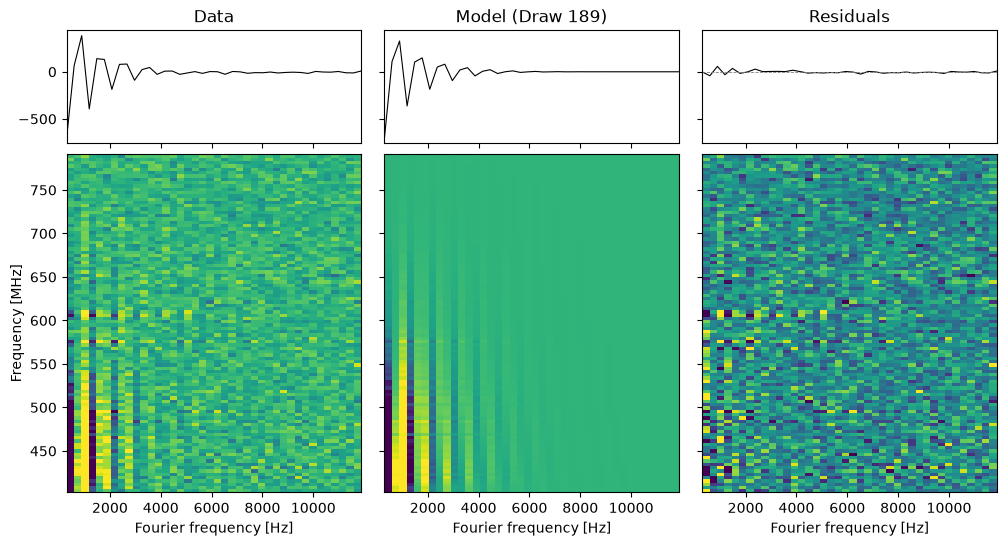

In [141]:
# -------------------------------------------------------------------
# 1. Forward model evaluation, Fourier domain
# -------------------------------------------------------------------
M_FD = single_pulse_fn(test_params) * A_scale

# data_reshaped_FFT and the model already live on the truncated Fourier axis, which is exactly
# the set of bins the likelihood uses, so nothing needs slicing here.
sigma_bins = jnp.broadcast_to(sigma_noise, data_reshaped_FFT.shape)

# Whitened, so all three panels are in units of sigma and the residual should be N(0, 1) noise
data_FD_plot = (data_reshaped_FFT / sigma_bins).real
model_FD_plot = (M_FD / sigma_bins).real
resid_FD_plot = data_FD_plot - model_FD_plot

fourier_plot = jnp.asarray(fourier_freqs).reshape(-1)
freq_plot = jnp.squeeze(freq)

print("Max Data abs :", jnp.max(jnp.abs(data_FD_plot)))
print("Max Model abs:", jnp.max(jnp.abs(model_FD_plot)))
print(f"whitened residual sd: {float(jnp.std(resid_FD_plot)):.3f}  (expect 1)")

# -------------------------------------------------------------------
# 2. Channel-summed spectra
# -------------------------------------------------------------------
data_ts = jnp.nansum(data_FD_plot, axis=0)
model_ts = jnp.nansum(model_FD_plot, axis=0)
resid_ts = data_ts - model_ts

# Data & Model limits
vmin, vmax = jnp.nanpercentile(data_FD_plot, jnp.array([1.0, 99.0]))

# Independent zero-centered limits for Residuals
vmax_res = jnp.nanpercentile(jnp.abs(resid_FD_plot), 99.0)

# -------------------------------------------------------------------
# 3. Figure Layout & Plotting
# -------------------------------------------------------------------
fig = plt.figure(figsize=(12, 6))
gs = gridspec.GridSpec(
    2,
    3,
    height_ratios=[1, 3],
    hspace=0.05,
    wspace=0.08,
    figure=fig,
)

ax_ts_data = fig.add_subplot(gs[0, 0])
ax_ts_model = fig.add_subplot(gs[0, 1], sharey=ax_ts_data)
ax_ts_resid = fig.add_subplot(gs[0, 2], sharey=ax_ts_data)

ax_wf_data = fig.add_subplot(gs[1, 0], sharex=ax_ts_data)
ax_wf_model = fig.add_subplot(gs[1, 1], sharex=ax_ts_model, sharey=ax_wf_data)
ax_wf_resid = fig.add_subplot(gs[1, 2], sharex=ax_ts_resid, sharey=ax_wf_data)

# --- Top row: channel-summed spectra ---
ax_ts_data.plot(fourier_plot, data_ts, color="k", lw=0.8)
ax_ts_model.plot(fourier_plot, model_ts, color="k", lw=0.8)
ax_ts_resid.plot(fourier_plot, resid_ts, color="k", lw=0.8)
ax_ts_resid.axhline(0, color="gray", lw=0.6, ls="--")

# --- Bottom row: Waterfalls ---
imshow_data_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
    vmin=vmin,
    vmax=vmax,
    extent=(fourier_plot[0], fourier_plot[-1], freq_plot[0], freq_plot[-1]),
)

imshow_resid_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
    vmin=-vmax_res,
    vmax=vmax_res,
    extent=(fourier_plot[0], fourier_plot[-1], freq_plot[0], freq_plot[-1]),
)

ax_wf_data.imshow(data_FD_plot, **imshow_data_kwargs)
ax_wf_model.imshow(model_FD_plot, **imshow_data_kwargs)
ax_wf_resid.imshow(resid_FD_plot, **imshow_resid_kwargs)

# --- Formatting ---
ax_ts_model.set_title(f"Model (Draw {draw_idx})")
ax_ts_data.set_title("Data")
ax_ts_resid.set_title("Residuals")

ax_wf_data.set_xlabel("Fourier frequency [Hz]")
ax_wf_model.set_xlabel("Fourier frequency [Hz]")
ax_wf_resid.set_xlabel("Fourier frequency [Hz]")
ax_wf_data.set_ylabel("Frequency [MHz]")

for ax in (ax_ts_data, ax_ts_model, ax_ts_resid):
    ax.tick_params(labelbottom=False)
for ax in (ax_ts_model, ax_wf_model, ax_ts_resid, ax_wf_resid):
    ax.tick_params(labelleft=False)

plt.tight_layout()
plt.show()

## Misc

In [48]:
# -------------------------------------------------------------------
# Check the basis weights against the fitted SED
# -------------------------------------------------------------------
# channel_weights were estimated from the data before sampling. The metric they should
# approximate is F_a^2 / varsigma_a^2, the per-channel signal power over noise variance, which
# we can now evaluate at the posterior median. If the two disagree badly the basis was
# orthogonalized in the wrong metric, which is one reason rho(c1, c2) would stay well above 0.
x = jnp.log(jnp.asarray(freq) / freq_channels_ref)
c1_med = float(jnp.median(jnp.asarray(samples["c1"])))
c2_med = float(jnp.median(jnp.asarray(samples["c2"])))

F_fit = jnp.exp(c1_med * jnp.asarray(P1).reshape(-1) + c2_med * jnp.asarray(P2).reshape(-1))
w_fit = (F_fit / jnp.asarray(sigma_estimates).reshape(-1)) ** 2
w_fit /= w_fit.sum()

w_used = jnp.asarray(channel_weights).reshape(-1)

print(f"correlation between weights used and fitted F^2/sigma^2: {jnp.corrcoef(w_used, w_fit)[0,1]:.4f}")
print(f"weight-weighted mean frequency:  used {jnp.sum(w_used*jnp.asarray(freq)):.1f} MHz, "
      f"fitted {jnp.sum(w_fit*jnp.asarray(freq)):.1f} MHz")

# What rho(c1, c2) the current basis would give under the fitted metric (Fisher prediction)
def fisher_rho(cols, w):
    J = jnp.stack(cols, axis=1)
    C = jnp.linalg.inv(J.T @ (w[:, None] * J))
    return C[0, 1] / jnp.sqrt(C[0, 0] * C[1, 1])

P1n, P2n = jnp.asarray(P1).reshape(-1), jnp.asarray(P2).reshape(-1)
print(f"Fisher rho(c1,c2) under fitted metric: {fisher_rho([P1n, P2n], w_fit):+.4f}")
print(f"Fisher rho(gamma,beta) for comparison: {fisher_rho([x, x**2], w_fit):+.4f}")

correlation between weights used and fitted F^2/sigma^2: 0.9204
weight-weighted mean frequency:  used 447.3 MHz, fitted 439.6 MHz
Fisher rho(c1,c2) under fitted metric: +0.5912
Fisher rho(gamma,beta) for comparison: +0.9886


In [49]:
import time
from numpyro.infer.util import potential_energy

# -------------------------------------------------------------------
# Is the sampler gradient-bound or overhead-bound?
# Time one jitted gradient of the potential energy, multiply by the gradients NUTS actually
# took, and compare with the measured wall time. If they agree, the likelihood dominates and
# a faster device or a smaller array will help; if the measured time is much larger, the cost
# is elsewhere (per-iteration Python, deterministic sites, host-device transfers).
# -------------------------------------------------------------------

model_args = ()
model_kwargs = dict(
    data_fd=data_reshaped_FFT,
    sigma_noise=sigma_noise,
    n_time=Nseg,
    n_pulses=n_pulses,
    priors=priors,
    single_pulse_fn=single_pulse_fn,
    s_opt=s_opt,
    spectral_coeff_map=spectral_coeff_map,
)

# Unconstrained position from the end of the chain, i.e. a realistic place to evaluate
z = mcmc.last_state.z

U = lambda z_: potential_energy(FD_marg_halfnormal_nooverlap_gaussianlikelihood,
                                model_args, model_kwargs, z_)
grad_U = jax.jit(jax.grad(U))

g = grad_U(z); jax.block_until_ready(g)          # compile once

n_rep = 200
t0 = time.perf_counter()
for _ in range(n_rep):
    g = grad_U(z)
jax.block_until_ready(g)
t_grad = (time.perf_counter() - t0) / n_rep

n_grad_total = int(jnp.sum(jnp.array(extra["num_steps"])))   # sampling phase only
print(f"one jitted gradient:        {t_grad*1e3:.3f} ms")
print(f"gradients during sampling:  {n_grad_total}")
print(f"predicted sampling time:    {t_grad*n_grad_total:.2f} s")
print(f"(compare with the measured wall time for the {num_samples} sampling iterations)")

TypeError: FD_marg_halfnormal_nooverlap_gaussianlikelihood() got an unexpected keyword argument 'n_time'

In [74]:
%timeit jax.block_until_ready(jax.jit(single_pulse_fn)(test_params))

223 μs ± 14.4 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)


In [75]:
print(single_pulse_fn(test_params).dtype)   # complex64, or complex128?

complex64


## Test priors

In [70]:

# -------------------------------------------------------------------
# 1. Forward Model Evaluation & IFFT Reconstruction
# -------------------------------------------------------------------
# Set test parameters matching your prior bounds
test_params = {
    "mean_arrival_time": jnp.float32(0.00115),  # (s)
    "sigma": jnp.float32(9.9871264e-05),             # (s)
    "DM": jnp.float32(-0.01),                 # residual DM (pc cm^-3)
    "tau_ref": jnp.float32(0.00017),          # scattering timescale (s)
    "gamma": jnp.float32(-5.6108313),               # spectral index
    "beta": jnp.float32(-2.6474257),                # spectral running
    "freq_ref": jnp.float32(600)
}

# Optional fluence scale (unit-template from setup_model scaled to data level)
A_scale = 4e-4

# Evaluate model in Fourier domain and transform to Time Domain
M_FD = single_pulse_fn(test_params) * A_scale
M_TD = (1.0 / dt) * jnp.fft.irfft(M_FD, n=Nseg, axis=-1)

# Reconstruct baseline-subtracted data in Time Domain
data_TD = (1.0 / dt) * jnp.fft.irfft(data_reshaped_FFT, n=Nseg, axis=-1)

# Convert to NumPy for Matplotlib rendering
data_TD_plot = jnp.asarray(data_TD)
model_TD_plot = jnp.asarray(M_TD)
time_plot = jnp.asarray(time_rel)
freq_plot = jnp.asarray(freq).squeeze()

# -------------------------------------------------------------------
# 2. Residuals & Frequency Collapsed Time Series
# -------------------------------------------------------------------
resid_TD_plot = data_TD_plot - model_TD_plot

# Frequency-summed time series
data_ts = jnp.nansum(data_TD_plot, axis=0)
model_ts = jnp.nansum(model_TD_plot, axis=0)
resid_ts = data_ts - model_ts

# Shared robust color limits
lo_pct, hi_pct = 1, 99
vmin, vmax = jnp.nanpercentile(data_TD_plot, [lo_pct, hi_pct])

# -------------------------------------------------------------------
# 3. Figure Layout & Plotting
# -------------------------------------------------------------------
fig = plt.figure(figsize=(12, 6))
gs = gridspec.GridSpec(
    2, 3,
    height_ratios=[1, 3],
    hspace=0.05, wspace=0.08,
    figure=fig,
)

ax_ts_data  = fig.add_subplot(gs[0, 0])
ax_ts_model = fig.add_subplot(gs[0, 1], sharey=ax_ts_data)
ax_ts_resid = fig.add_subplot(gs[0, 2], sharey=ax_ts_data)

ax_wf_data  = fig.add_subplot(gs[1, 0], sharex=ax_ts_data)
ax_wf_model = fig.add_subplot(gs[1, 1], sharex=ax_ts_model, sharey=ax_wf_data)
ax_wf_resid = fig.add_subplot(gs[1, 2], sharex=ax_ts_resid, sharey=ax_wf_data)

# --- Top row: Frequency-summed time series ---
ax_ts_data.plot(time_plot, data_ts, color="k", lw=0.8)
ax_ts_model.plot(time_plot, model_ts, color="k", lw=0.8)
ax_ts_resid.plot(time_plot, resid_ts, color="k", lw=0.8)
ax_ts_resid.axhline(0, color="gray", lw=0.6, ls="--")

# --- Bottom row: Waterfalls ---
imshow_kwargs = dict(
    aspect="auto",
    origin="lower",
    interpolation="nearest",
    cmap="viridis",
    vmin=vmin,
    vmax=vmax,
    extent=(time_plot[0], time_plot[-1], freq_plot[0], freq_plot[-1]),
)

ax_wf_data.imshow(data_TD_plot, **imshow_kwargs)
ax_wf_model.imshow(model_TD_plot, **imshow_kwargs)
ax_wf_resid.imshow(resid_TD_plot, **imshow_kwargs)

# --- Formatting ---
ax_ts_data.set_title("Data")
ax_ts_model.set_title("Model")
ax_ts_resid.set_title("Residuals")

ax_wf_data.set_xlabel("Time [s]")
ax_wf_model.set_xlabel("Time [s]")
ax_wf_resid.set_xlabel("Time [s]")
ax_wf_data.set_ylabel("Frequency [MHz]")

for ax in (ax_ts_data, ax_ts_model, ax_ts_resid):
    ax.tick_params(labelbottom=False)
for ax in (ax_ts_model, ax_wf_model, ax_ts_resid, ax_wf_resid):
    ax.tick_params(labelleft=False)

plt.tight_layout()
plt.show()

KeyError: 'c1'